#Simple Coin Toss Simulation

Installs the quantum stack, in this case Cirq by Google

In [1]:
!pip install cirq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 7.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 733.7/733.7 kB 10.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 20.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 18.9 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [cirq]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.


Import Cirq and matplotlib for visualization

In [2]:
import cirq
import matplotlib.pyplot as plt

In [3]:
# Define a qubit
qubit = cirq.GridQubit(0, 0)

# Create a circuit
qc = cirq.Circuit()

# Apply the Hadamard gate to put the qubit in superposition (the "coin flip")
qc.append(cirq.H(qubit))

# Measure the qubit
qc.append(cirq.measure(qubit, key='coin_flip'))

# Display the circuit diagram
print("Circuit Diagram:")
print(qc)

Circuit Diagram:
(0, 0): ───H───M('coin_flip')───


In [4]:
# Initialize the Cirq simulator
simulator = cirq.Simulator()

# Run the simulation 1,000 times
result = simulator.run(qc, repetitions=1000)

# Get the counts of the measurement outcomes
counts = result.histogram(key='coin_flip')

# Map integer keys to labels for clarity
counts_labeled = {'Heads (0)': counts.get(0, 0), 'Tails (1)': counts.get(1, 0)}
print("Flip Results:", counts_labeled)

Flip Results: {'Heads (0)': 499, 'Tails (1)': 501}


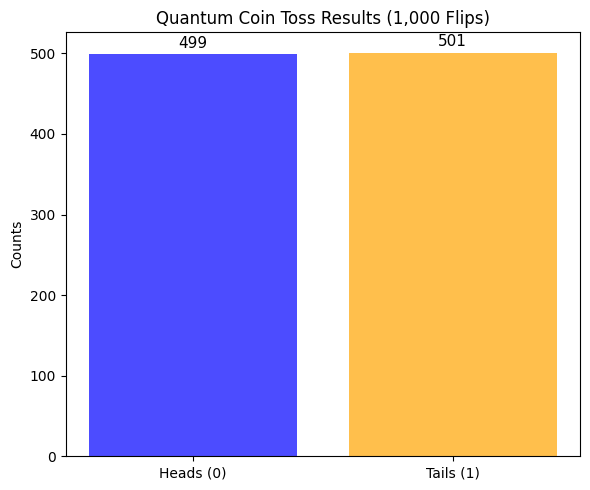

In [5]:
# Visualizing the results using standard matplotlib
fig, ax = plt.subplots(figsize=(6, 5))
ax.bar(counts_labeled.keys(), counts_labeled.values(), color=['blue', 'orange'], alpha=0.7)
ax.set_ylabel('Counts')
ax.set_title('Quantum Coin Toss Results (1,000 Flips)')

# Add value labels on top of the bars
for bar in ax.patches:
    ax.annotate(format(bar.get_height(), '.0f'),
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='center',
                size=11, xytext=(0, 8),
                textcoords='offset points')

plt.tight_layout()
plt.show()

Plotting a histogram showing the frequency of Heads vs. Tails. Because of quantum superposition, The bars should be roughly 50/50